# HR Job Change Prediction — Model Training and Evaluation

This notebook prepares the cleaned HR Analytics dataset for machine learning,
builds leakage-safe preprocessing pipelines, trains and tunes four models,
and evaluates their performance.

Models:
- Logistic Regression
- K-Nearest Neighbors (KNN)
- Decision Tree
- Random Forest

The final test set will remain untouched until final model evaluation.

In [1]:
import warnings
from pathlib import Path
import pickle

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
PROJECT_ROOT = Path.cwd().parent

CLEAN_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "clean_hr_job_change.csv"
)

ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"

print("Project root:", PROJECT_ROOT)
print("Clean dataset:", CLEAN_DATA_PATH)
print("Artifacts directory:", ARTIFACTS_DIR)

Project root: e:\hr-job-change-ml
Clean dataset: e:\hr-job-change-ml\data\processed\clean_hr_job_change.csv
Artifacts directory: e:\hr-job-change-ml\artifacts


In [3]:
df = pd.read_csv(CLEAN_DATA_PATH)
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (19158, 16)

Columns:
['enrollee_id', 'city', 'city_development_index', 'gender', 'relevent_experience', 'enrolled_university', 'education_level', 'major_discipline', 'company_size', 'company_type', 'training_hours', 'target', 'experience_missing', 'experience_numeric', 'last_new_job_missing', 'last_new_job_numeric']


In [4]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate enrollee IDs:", df["enrollee_id"].duplicated().sum())

print("\nTarget distribution:")
print(df["target"].value_counts())

print("\nTarget proportions:")
print(df["target"].value_counts(normalize=True))

Duplicate rows: 0
Duplicate enrollee IDs: 0

Target distribution:
target
0.0    14381
1.0     4777
Name: count, dtype: int64

Target proportions:
target
0.0    0.750652
1.0    0.249348
Name: proportion, dtype: float64


In [5]:
ID_COLUMN = "enrollee_id"
TARGET_COLUMN = "target"

X = df.drop(columns=[ID_COLUMN, TARGET_COLUMN])
y = df[TARGET_COLUMN]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Feature shape: (19158, 14)
Target shape: (19158,)

Features:
['city', 'city_development_index', 'gender', 'relevent_experience', 'enrolled_university', 'education_level', 'major_discipline', 'company_size', 'company_type', 'training_hours', 'experience_missing', 'experience_numeric', 'last_new_job_missing', 'last_new_job_numeric']


In [6]:
print("Unique target values:", sorted(y.unique()))
print("Number of classes:", y.nunique())

Unique target values: [np.float64(0.0), np.float64(1.0)]
Number of classes: 2


The cleaned dataset is divided into:
- 85% development/training data
- 15% final test data

The final test set will remain untouched during preprocessing design, cross-validation, hyperparameter tuning, and threshold selection.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training/development set:", X_train.shape)
print("Final test set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))

Training/development set: (16284, 14)
Final test set: (2874, 14)

Training target distribution:
target
0.0    0.750676
1.0    0.249324
Name: proportion, dtype: float64

Test target distribution:
target
0.0    0.750522
1.0    0.249478
Name: proportion, dtype: float64


## Feature Groups

Numerical features will be imputed and scaled where appropriate.
Categorical features will be imputed and one-hot encoded.

All transformations will be placed inside scikit-learn pipelines so that they are learned only from the training data during cross-validation.

In [8]:
numeric_features = [
    "city_development_index",
    "training_hours",
    "experience_missing",
    "experience_numeric",
    "last_new_job_missing",
    "last_new_job_numeric"
]

categorical_features = [
    "city",
    "gender",
    "relevent_experience",
    "enrolled_university",
    "education_level",
    "major_discipline",
    "company_size",
    "company_type"
]

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTotal features:", len(numeric_features) + len(categorical_features))

Numerical features:
['city_development_index', 'training_hours', 'experience_missing', 'experience_numeric', 'last_new_job_missing', 'last_new_job_numeric']

Categorical features:
['city', 'gender', 'relevent_experience', 'enrolled_university', 'education_level', 'major_discipline', 'company_size', 'company_type']

Total features: 14


In [10]:
print("Training-set missing values:")
print(X_train.isna().sum().sort_values(ascending=False))

Training-set missing values:
last_new_job_numeric      364
experience_numeric         57
gender                      0
relevent_experience         0
city                        0
city_development_index      0
education_level             0
enrolled_university         0
major_discipline            0
company_size                0
training_hours              0
company_type                0
experience_missing          0
last_new_job_missing        0
dtype: int64


In [ ]:
numeric_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

print("Numerical preprocessing pipeline created.")

Numerical preprocessing pipeline created.


In [12]:
categorical_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)

print("Categorical preprocessing pipeline created.")

Categorical preprocessing pipeline created.


In [13]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_preprocessor, numeric_features),
        ("cat", categorical_preprocessor, categorical_features)
    ]
)

print("Combined preprocessing pipeline created.")

Combined preprocessing pipeline created.


In [14]:
X_train_processed = preprocessor.fit_transform(X_train)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)
print("Processed data type:", type(X_train_processed))

Original training shape: (16284, 14)
Processed training shape: (16284, 145)
Processed data type: <class 'scipy.sparse._csr.csr_matrix'>


In [15]:
X_test_processed = preprocessor.transform(X_test)

print("Processed test shape:", X_test_processed.shape)

Processed test shape: (2874, 145)


In [16]:
def create_model_pipeline(model):
    return Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

print("Model pipeline helper created.")

Model pipeline helper created.


## Baseline Model Pipelines

Four baseline classification models will be evaluated:

1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Decision Tree
4. Random Forest

Each model will contain its own preprocessing pipeline so that preprocessing is performed without data leakage.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print("Model libraries imported successfully.")

Model libraries imported successfully.


In [18]:
logistic_model = create_model_pipeline(
    LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    )
)

print("Logistic Regression pipeline created.")

Logistic Regression pipeline created.


In [19]:
knn_model = create_model_pipeline(
    KNeighborsClassifier(
        n_neighbors=5
    )
)

print("KNN pipeline created.")

KNN pipeline created.


In [20]:
decision_tree_model = create_model_pipeline(
    DecisionTreeClassifier(
        random_state=RANDOM_STATE
    )
)

print("Decision Tree pipeline created.")

Decision Tree pipeline created.


In [21]:
random_forest_model = create_model_pipeline(
    RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
)

print("Random Forest pipeline created.")

Random Forest pipeline created.


In [22]:
models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

print("Models prepared:")
for name in models:
    print("-", name)

Models prepared:
- Logistic Regression
- KNN
- Decision Tree
- Random Forest


In [23]:
baseline_results = []

for name, model in models.items():
    print(f"Training {name}...")
    
    model.fit(X_train, y_train)
    
    print(f"{name} trained successfully.")

Training Logistic Regression...
Logistic Regression trained successfully.
Training KNN...
KNN trained successfully.
Training Decision Tree...
Decision Tree trained successfully.
Training Random Forest...
Random Forest trained successfully.


In [24]:
baseline_predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_train)
    y_prob = model.predict_proba(X_train)[:, 1]
    
    baseline_predictions[name] = {
        "y_pred": y_pred,
        "y_prob": y_prob
    }

print("Baseline predictions generated.")

Baseline predictions generated.


In [25]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss
)

print("Evaluation metrics imported.")

Evaluation metrics imported.


In [26]:
training_check_results = []

for name, prediction_data in baseline_predictions.items():
    y_pred = prediction_data["y_pred"]
    y_prob = prediction_data["y_prob"]
    
    training_check_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_train, y_pred),
        "Precision": precision_score(y_train, y_pred),
        "Recall": recall_score(y_train, y_pred),
        "F1": f1_score(y_train, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_train, y_pred),
        "ROC-AUC": roc_auc_score(y_train, y_prob),
        "PR-AUC": average_precision_score(y_train, y_prob),
        "Log Loss": log_loss(y_train, y_prob),
        "Brier Score": brier_score_loss(y_train, y_prob)
    })

training_check_df = pd.DataFrame(training_check_results)

training_check_df.sort_values(
    "PR-AUC",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss,Brier Score
3,Random Forest,0.999017,0.998521,0.997537,0.998029,0.998523,0.999996,0.999987,0.115974,0.021093
2,Decision Tree,0.999017,1.000000,0.996059,0.998026,0.998030,0.999997,0.999985,0.001394,0.000502
1,KNN,0.835667,0.695480,0.606404,0.647895,0.759108,0.887989,0.672478,0.334188,0.112903
0,Logistic Regression,0.783039,0.606036,0.370936,0.460199,0.645424,0.803101,0.551062,0.448115,0.143330


## Baseline Cross-Validation

The development dataset is evaluated using 5-fold stratified cross-validation.

The final test set remains untouched.

PR-AUC is used as the primary comparison metric because the positive class represents approximately 25% of the dataset.

In [27]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "neg_log_loss": "neg_log_loss",
    "neg_brier": "neg_brier_score"
}

print("5-fold stratified cross-validation configured.")

5-fold stratified cross-validation configured.


In [28]:
cv_results = []

for name, model in models.items():
    print(f"Running 5-fold CV for {name}...")
    
    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )
    
    cv_results.append({
        "Model": name,
        "Accuracy": results["test_accuracy"].mean(),
        "Precision": results["test_precision"].mean(),
        "Recall": results["test_recall"].mean(),
        "F1": results["test_f1"].mean(),
        "Balanced Accuracy": results["test_balanced_accuracy"].mean(),
        "ROC-AUC": results["test_roc_auc"].mean(),
        "PR-AUC": results["test_pr_auc"].mean(),
        "Log Loss": -results["test_neg_log_loss"].mean(),
        "Brier Score": -results["test_neg_brier"].mean()
    })
    
    print(f"{name} completed.")

Running 5-fold CV for Logistic Regression...
Logistic Regression completed.
Running 5-fold CV for KNN...
KNN completed.
Running 5-fold CV for Decision Tree...
Decision Tree completed.
Running 5-fold CV for Random Forest...
Random Forest completed.


In [29]:
baseline_cv_df = pd.DataFrame(cv_results)

baseline_cv_df = baseline_cv_df.sort_values(
    "PR-AUC",
    ascending=False
).reset_index(drop=True)

baseline_cv_df

,Model,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss,Brier Score
0,Logistic Regression,0.779722,0.596394,0.360837,0.449456,0.639842,0.793279,0.539324,0.456225,0.146001
1,Random Forest,0.783161,0.581777,0.465517,0.516994,0.677089,0.785666,0.528629,0.499956,0.149406
2,KNN,0.767071,0.537372,0.474138,0.503720,0.669251,0.754039,0.459024,1.980551,0.167510
3,Decision Tree,0.724699,0.449022,0.457882,0.453286,0.635600,0.635870,0.341050,9.910497,0.275270


In [30]:
print("Baseline models ranked by PR-AUC:\n")

print(
    baseline_cv_df[
        ["Model", "PR-AUC", "ROC-AUC", "F1", "Recall", "Precision", "Accuracy"]
    ].to_string(index=False)
)

Baseline models ranked by PR-AUC:

              Model   PR-AUC  ROC-AUC       F1   Recall  Precision  Accuracy
Logistic Regression 0.539324 0.793279 0.449456 0.360837   0.596394  0.779722
      Random Forest 0.528629 0.785666 0.516994 0.465517   0.581777  0.783161
                KNN 0.459024 0.754039 0.503720 0.474138   0.537372  0.767071
      Decision Tree 0.341050 0.635870 0.453286 0.457882   0.449022  0.724699


In [31]:
from sklearn.model_selection import GridSearchCV

In [ ]:
param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"]
    },

    "KNN": {
        "model__n_neighbors": [3, 5, 7, 11, 15, 21],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]
    },

    "Decision Tree": {
        "model__max_depth": [3, 5, 7, 10, 15, None],
        "model__min_samples_split": [2, 5, 10, 20],
        "model__min_samples_leaf": [1, 2, 5, 10],
        "model__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 5],
        "model__class_weight": [None, "balanced"]
    }
}

In [33]:
tuned_models = {}
tuning_results = []

for name, model in models.items():

    print(f"\nTuning {name}...")

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring="average_precision",
        cv=cv,
        n_jobs=-1,
        verbose=1,
        return_train_score=False
    )

    grid_search.fit(X_train, y_train)

    tuned_models[name] = grid_search

    tuning_results.append({
        "Model": name,
        "Best PR-AUC": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    })

    print(f"Best PR-AUC: {grid_search.best_score_:.4f}")
    print("Best parameters:")
    print(grid_search.best_params_)


Tuning Logistic Regression...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best PR-AUC: 0.5424
Best parameters:
{'model__C': 0.1, 'model__class_weight': None}

Tuning KNN...
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best PR-AUC: 0.5240
Best parameters:
{'model__n_neighbors': 21, 'model__p': 1, 'model__weights': 'uniform'}

Tuning Decision Tree...
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Best PR-AUC: 0.5250
Best parameters:
{'model__class_weight': None, 'model__max_depth': 7, 'model__min_samples_leaf': 5, 'model__min_samples_split': 20}

Tuning Random Forest...
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best PR-AUC: 0.5531
Best parameters:
{'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 5, 'model__min_samples_split': 2, 'model__n_estimators': 200}


In [34]:
tuning_summary_df = pd.DataFrame(tuning_results)

tuning_summary_df = tuning_summary_df.sort_values(
    "Best PR-AUC",
    ascending=False
).reset_index(drop=True)

tuning_summary_df

,Model,Best PR-AUC,Best Parameters
0,Random Forest,0.553074,"{'model__class_weight': 'balanced', 'model__ma..."
1,Logistic Regression,0.542403,"{'model__C': 0.1, 'model__class_weight': None}"
2,Decision Tree,0.524982,"{'model__class_weight': None, 'model__max_dept..."
3,KNN,0.524014,"{'model__n_neighbors': 21, 'model__p': 1, 'mod..."


In [35]:
for name, search in tuned_models.items():

    print("=" * 70)
    print(name)
    print("=" * 70)

    print(f"Best CV PR-AUC: {search.best_score_:.4f}")
    print("Best parameters:")

    for parameter, value in search.best_params_.items():
        print(f"  {parameter}: {value}")

    print()

Logistic Regression
Best CV PR-AUC: 0.5424
Best parameters:
  model__C: 0.1
  model__class_weight: None

KNN
Best CV PR-AUC: 0.5240
Best parameters:
  model__n_neighbors: 21
  model__p: 1
  model__weights: uniform

Decision Tree
Best CV PR-AUC: 0.5250
Best parameters:
  model__class_weight: None
  model__max_depth: 7
  model__min_samples_leaf: 5
  model__min_samples_split: 20

Random Forest
Best CV PR-AUC: 0.5531
Best parameters:
  model__class_weight: balanced
  model__max_depth: None
  model__min_samples_leaf: 5
  model__min_samples_split: 2
  model__n_estimators: 200



In [36]:
import numpy as np
import pandas as pd

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss
)

In [37]:
oof_probabilities = {}

for name, search in tuned_models.items():

    print(f"Generating OOF probabilities for {name}...")

    best_model = search.best_estimator_

    oof_prob = cross_val_predict(
        best_model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    oof_probabilities[name] = oof_prob

    print(f"Completed {name}.")

Generating OOF probabilities for Logistic Regression...
Completed Logistic Regression.
Generating OOF probabilities for KNN...
Completed KNN.
Generating OOF probabilities for Decision Tree...
Completed Decision Tree.
Generating OOF probabilities for Random Forest...
Completed Random Forest.


In [38]:
oof_check_df = pd.DataFrame({"Actual": y_train.reset_index(drop=True)})

for name, probabilities in oof_probabilities.items():
    oof_check_df[name] = probabilities

oof_check_df.head(10)

,Actual,Logistic Regression,KNN,Decision Tree,Random Forest
0,0.0,0.062140,0.142857,0.066639,0.197866
1,0.0,0.392648,0.476190,0.465812,0.742940
2,0.0,0.496809,0.571429,0.532095,0.736519
3,0.0,0.036405,0.095238,0.091333,0.198028
4,0.0,0.128158,0.047619,0.056738,0.148504
5,1.0,0.512329,0.761905,0.546131,0.804989
6,0.0,0.052425,0.190476,0.066639,0.240702
7,0.0,0.049007,0.000000,0.070994,0.142905
8,0.0,0.132268,0.000000,0.066773,0.198571
9,0.0,0.100017,0.047619,0.035461,0.199945


In [39]:
oof_pr_auc_results = []

for name, probabilities in oof_probabilities.items():

    pr_auc = average_precision_score(
        y_train,
        probabilities
    )

    roc_auc = roc_auc_score(
        y_train,
        probabilities
    )

    oof_pr_auc_results.append({
        "Model": name,
        "OOF PR-AUC": pr_auc,
        "OOF ROC-AUC": roc_auc
    })

oof_auc_df = (
    pd.DataFrame(oof_pr_auc_results)
    .sort_values("OOF PR-AUC", ascending=False)
    .reset_index(drop=True)
)

oof_auc_df

,Model,OOF PR-AUC,OOF ROC-AUC
0,Random Forest,0.550325,0.801359
1,Logistic Regression,0.540495,0.794741
2,Decision Tree,0.528112,0.790751
3,KNN,0.522950,0.789725


## Threashold Analysis

In [40]:
thresholds = np.arange(0.10, 0.91, 0.01)
print(f"Number of thresholds tested: {len(thresholds)}")

Number of thresholds tested: 81


In [43]:
threshold_results = []

for name, probabilities in oof_probabilities.items():

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_train, predictions),
            "Precision": precision_score(
                y_train,
                predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_train,
                predictions,
                zero_division=0
            ),
            "F1": f1_score(
                y_train,
                predictions,
                zero_division=0
            ),
            "Balanced Accuracy": balanced_accuracy_score(
                y_train,
                predictions
            )
        })

threshold_results_df = pd.DataFrame(threshold_results)
print(threshold_results_df.head())
print(threshold_results_df.tail())

                 Model  Threshold  Accuracy  Precision    Recall        F1  \
0  Logistic Regression       0.10  0.478384   0.313760  0.919951  0.467928   
1  Logistic Regression       0.11  0.508843   0.325133  0.901724  0.477937   
2  Logistic Regression       0.12  0.539732   0.338262  0.884729  0.489407   
3  Logistic Regression       0.13  0.573999   0.355703  0.873399  0.505524   
4  Logistic Regression       0.14  0.607406   0.374691  0.859113  0.521804   

   Balanced Accuracy  
0           0.625838  
1           0.640039  
2           0.654938  
3           0.673979  
4           0.691459  
             Model  Threshold  Accuracy  Precision    Recall        F1  \
319  Random Forest       0.86  0.751044   0.636364  0.003448  0.006859   
320  Random Forest       0.87  0.750553   0.333333  0.000493  0.000984   
321  Random Forest       0.88  0.750676   0.000000  0.000000  0.000000   
322  Random Forest       0.89  0.750676   0.000000  0.000000  0.000000   
323  Random Forest     

In [45]:
best_threshold_rows = []

for name in oof_probabilities.keys():

    model_results = threshold_results_df[threshold_results_df["Model"] == name]
    best_row = model_results.loc[model_results["F1"].idxmax()]
    best_threshold_rows.append({
        "Model": name,
        "Best Threshold": best_row["Threshold"],
        "F1": best_row["F1"],
        "Precision": best_row["Precision"],
        "Recall": best_row["Recall"],
        "Accuracy": best_row["Accuracy"],
        "Balanced Accuracy": best_row["Balanced Accuracy"]
    })

best_threshold_df = pd.DataFrame(best_threshold_rows).sort_values("F1", ascending=False).reset_index(drop=True)

In [46]:
for _, row in best_threshold_df.iterrows():

    print("=" * 70)
    print(row["Model"])
    print("=" * 70)

    print(f"Best threshold:       {row['Best Threshold']:.2f}")
    print(f"F1:                   {row['F1']:.4f}")
    print(f"Precision:            {row['Precision']:.4f}")
    print(f"Recall:               {row['Recall']:.4f}")
    print(f"Accuracy:             {row['Accuracy']:.4f}")
    print(f"Balanced Accuracy:    {row['Balanced Accuracy']:.4f}")
    print()

Random Forest
Best threshold:       0.56
F1:                   0.6337
Precision:            0.5723
Recall:               0.7099
Accuracy:             0.7954
Balanced Accuracy:    0.7668

Logistic Regression
Best threshold:       0.30
F1:                   0.6241
Precision:            0.5590
Recall:               0.7064
Accuracy:             0.7878
Balanced Accuracy:    0.7606

Decision Tree
Best threshold:       0.31
F1:                   0.6217
Precision:            0.5537
Recall:               0.7086
Accuracy:             0.7849
Balanced Accuracy:    0.7595

KNN
Best threshold:       0.34
F1:                   0.6088
Precision:            0.5311
Recall:               0.7131
Accuracy:             0.7715
Balanced Accuracy:    0.7520



In [47]:
threshold_comparison = []

for name, probabilities in oof_probabilities.items():

    # Default threshold
    default_predictions = (probabilities >= 0.50).astype(int)

    default_f1 = f1_score(
        y_train,
        default_predictions,
        zero_division=0
    )

    default_precision = precision_score(
        y_train,
        default_predictions,
        zero_division=0
    )

    default_recall = recall_score(
        y_train,
        default_predictions,
        zero_division=0
    )

    # Tuned threshold
    tuned_threshold = best_threshold_df.loc[best_threshold_df["Model"] == name,"Best Threshold"].iloc[0]
    tuned_predictions = (probabilities >= tuned_threshold).astype(int)

    tuned_f1 = f1_score(
        y_train,
        tuned_predictions,
        zero_division=0
    )

    tuned_precision = precision_score(
        y_train,
        tuned_predictions,
        zero_division=0
    )

    tuned_recall = recall_score(
        y_train,
        tuned_predictions,
        zero_division=0
    )

    threshold_comparison.append({
        "Model": name,
        "Default Threshold": 0.50,
        "Tuned Threshold": tuned_threshold,
        "Default F1": default_f1,
        "Tuned F1": tuned_f1,
        "Default Precision": default_precision,
        "Tuned Precision": tuned_precision,
        "Default Recall": default_recall,
        "Tuned Recall": tuned_recall
    })

threshold_comparison_df = pd.DataFrame(threshold_comparison)
threshold_comparison_df

,Model,Default Threshold,Tuned Threshold,Default F1,Tuned F1,Default Precision,Tuned Precision,Default Recall,Tuned Recall
0,Logistic Regression,0.5,0.30,0.436130,0.624089,0.598368,0.558955,0.343103,0.706404
1,KNN,0.5,0.34,0.558940,0.608769,0.579086,0.531095,0.540148,0.713054
2,Decision Tree,0.5,0.31,0.585450,0.621651,0.583231,0.553695,0.587685,0.708621
3,Random Forest,0.5,0.56,0.630471,0.633685,0.550331,0.572280,0.737931,0.709852


In [51]:
selected_thresholds = {
    row["Model"]: float(row["Best Threshold"])
    for _, row in best_threshold_df.iterrows()
}

In [49]:
final_models = {}

for name, search in tuned_models.items():

    print(f"Fitting final development model: {name}...")
    final_model = search.best_estimator_
    final_model.fit(
        X_train,
        y_train
    )
    final_models[name] = final_model
    print(f"{name} fitted successfully.")

Fitting final development model: Logistic Regression...
Logistic Regression fitted successfully.
Fitting final development model: KNN...
KNN fitted successfully.
Fitting final development model: Decision Tree...
Decision Tree fitted successfully.
Fitting final development model: Random Forest...
Random Forest fitted successfully.


In [50]:
test_probabilities = {}

for name, model in final_models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    test_probabilities[name] = probabilities
    print(f"{name}: test probabilities generated.")

Logistic Regression: test probabilities generated.
KNN: test probabilities generated.
Decision Tree: test probabilities generated.
Random Forest: test probabilities generated.


In [52]:
test_predictions = {}

for name, probabilities in test_probabilities.items():
    threshold = selected_thresholds[name]
    predictions = (probabilities >= threshold).astype(int)
    test_predictions[name] = predictions

In [55]:
final_test_results = []

for name in final_models.keys():
    probabilities = test_probabilities[name]
    predictions = test_predictions[name]

    final_test_results.append({
        "Model": name,
        "Threshold": selected_thresholds[name],
        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test,
            predictions
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            probabilities
        ),
        "PR-AUC": average_precision_score(
            y_test,
            probabilities
        ),
        "Log Loss": log_loss(
            y_test,
            probabilities
        ),
        "Brier Score": brier_score_loss(
            y_test,
            probabilities
        )
    })

final_test_df = pd.DataFrame(final_test_results).sort_values("PR-AUC", ascending=False).reset_index(drop=True)

In [56]:
print("FINAL TEST SET RESULTS")
print("=" * 100)
print(final_test_df.round(4))

FINAL TEST SET RESULTS
                 Model  Threshold  Accuracy  Precision  Recall      F1  \
0  Logistic Regression       0.30    0.7888     0.5579  0.7392  0.6359   
1        Random Forest       0.56    0.7954     0.5687  0.7448  0.6449   
2        Decision Tree       0.31    0.7867     0.5545  0.7378  0.6332   
3                  KNN       0.34    0.7773     0.5390  0.7420  0.6244   

   Balanced Accuracy  ROC-AUC  PR-AUC  Log Loss  Brier Score  
0             0.7722   0.8060  0.5450    0.4484       0.1434  
1             0.7785   0.8094  0.5443    0.5196       0.1688  
2             0.7704   0.8030  0.5343    0.5067       0.1399  
3             0.7655   0.7986  0.5117    0.5709       0.1450  


In [57]:
cv_vs_test_results = []

for name in final_models.keys():
    cv_pr_auc = tuned_models[name].best_score_
    test_pr_auc = final_test_df.loc[final_test_df["Model"] == name,"PR-AUC"].iloc[0]
    cv_vs_test_results.append({
        "Model": name,
        "Best CV PR-AUC": cv_pr_auc,
        "Test PR-AUC": test_pr_auc,
        "Difference": test_pr_auc - cv_pr_auc
    })

cv_vs_test_df = pd.DataFrame(cv_vs_test_results).sort_values("Test PR-AUC", ascending=False).reset_index(drop=True)
cv_vs_test_df.round(4)

,Model,Best CV PR-AUC,Test PR-AUC,Difference
0,Logistic Regression,0.5424,0.5450,0.0026
1,Random Forest,0.5531,0.5443,-0.0087
2,Decision Tree,0.5250,0.5343,0.0093
3,KNN,0.5240,0.5117,-0.0123


In [58]:
final_ranking_df = final_test_df[
    [
        "Model",
        "PR-AUC",
        "ROC-AUC",
        "F1",
        "Recall",
        "Precision",
        "Accuracy",
        "Balanced Accuracy",
        "Log Loss",
        "Brier Score",
        "Threshold"
    ]
].copy()

final_ranking_df

,Model,PR-AUC,ROC-AUC,F1,Recall,Precision,Accuracy,Balanced Accuracy,Log Loss,Brier Score,Threshold
0,Logistic Regression,0.545018,0.806008,0.635873,0.739191,0.557895,0.788796,0.772238,0.448365,0.143417,0.30
1,Random Forest,0.544331,0.809383,0.644928,0.744770,0.568690,0.795407,0.778505,0.519626,0.168815,0.56
2,Decision Tree,0.534296,0.803015,0.633154,0.737796,0.554507,0.786708,0.770382,0.506655,0.139861,0.31
3,KNN,0.511702,0.798552,0.624413,0.741980,0.539007,0.777314,0.765520,0.570866,0.145035,0.34


## Visual Evaluation of models

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)
from sklearn.calibration import calibration_curve

In [81]:
from pathlib import Path

plots_dir = Path("../artifacts/plots")

plots_dir.mkdir(
    parents=True,
    exist_ok=True
)

print(f"Plots directory: {plots_dir.resolve()}")

Plots directory: E:\hr-job-change-ml\artifacts\plots


In [60]:
confusion_matrices = {}

for name in final_models.keys():
    cm = confusion_matrix(y_test,test_predictions[name])
    confusion_matrices[name] = cm
    print(f"{name}")
    print(cm)
    print()

Logistic Regression
[[1737  420]
 [ 187  530]]

KNN
[[1702  455]
 [ 185  532]]

Decision Tree
[[1732  425]
 [ 188  529]]

Random Forest
[[1752  405]
 [ 183  534]]



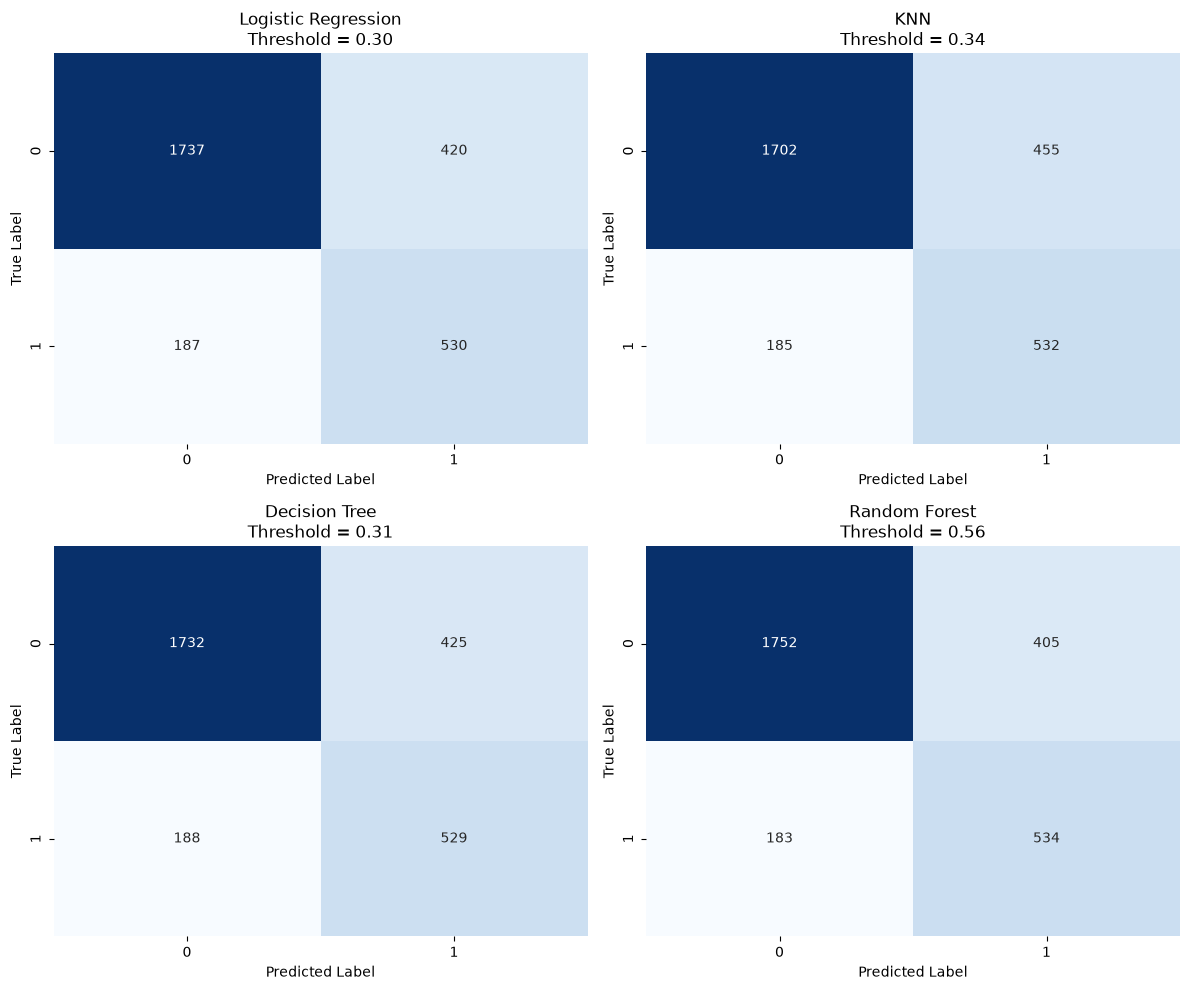

In [82]:
fig, axes = plt.subplots(2,2,figsize=(12, 10))
axes = axes.ravel()

for ax, name in zip(axes, final_models.keys()):
    cm = confusion_matrices[name]
    sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",cbar=False,ax=ax)
    ax.set_title(f"{name}\nThreshold = {selected_thresholds[name]:.2f}")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()

plt.savefig(
    plots_dir / "confusion_matrices.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [62]:
roc_curve_data = {}

for name, probabilities in test_probabilities.items():

    fpr, tpr, thresholds_roc = roc_curve(y_test,probabilities)

    roc_curve_data[name] = {
        "fpr": fpr,
        "tpr": tpr,
        "thresholds": thresholds_roc
    }

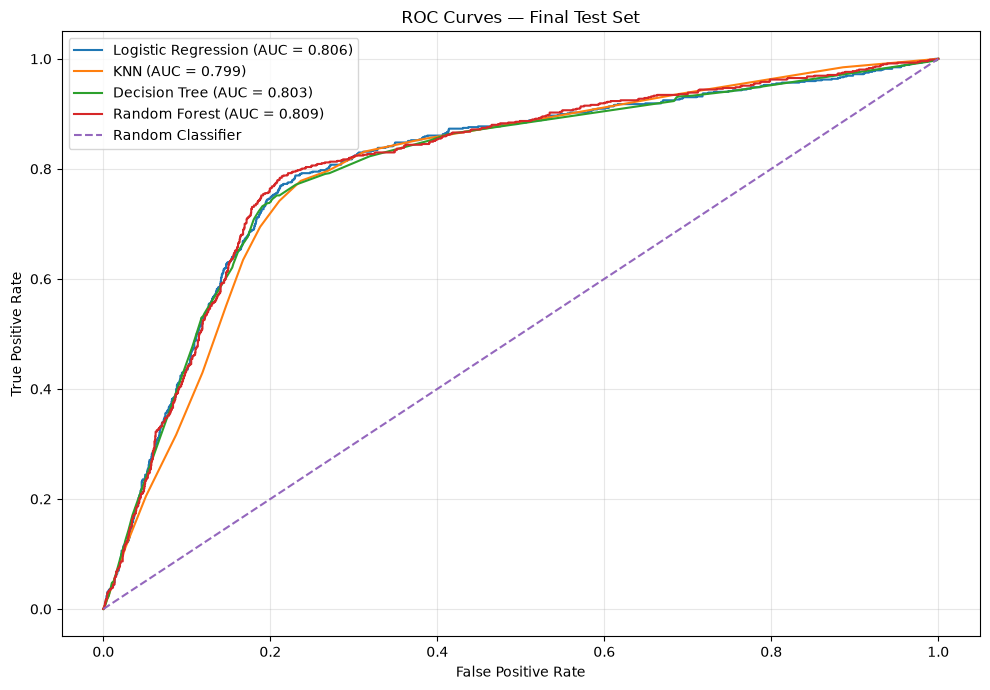

In [84]:
plt.figure(figsize=(10, 7))

for name, data in roc_curve_data.items():

    roc_auc = roc_auc_score(y_test,test_probabilities[name])

    plt.plot(
        data["fpr"],
        data["tpr"],
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1],[0, 1],linestyle="--",label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Final Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    plots_dir / "roc_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [64]:
pr_curve_data = {}

for name, probabilities in test_probabilities.items():
    precision, recall, thresholds_pr = precision_recall_curve(y_test,probabilities)
    pr_curve_data[name] = {
        "precision": precision,
        "recall": recall,
        "thresholds": thresholds_pr
    }

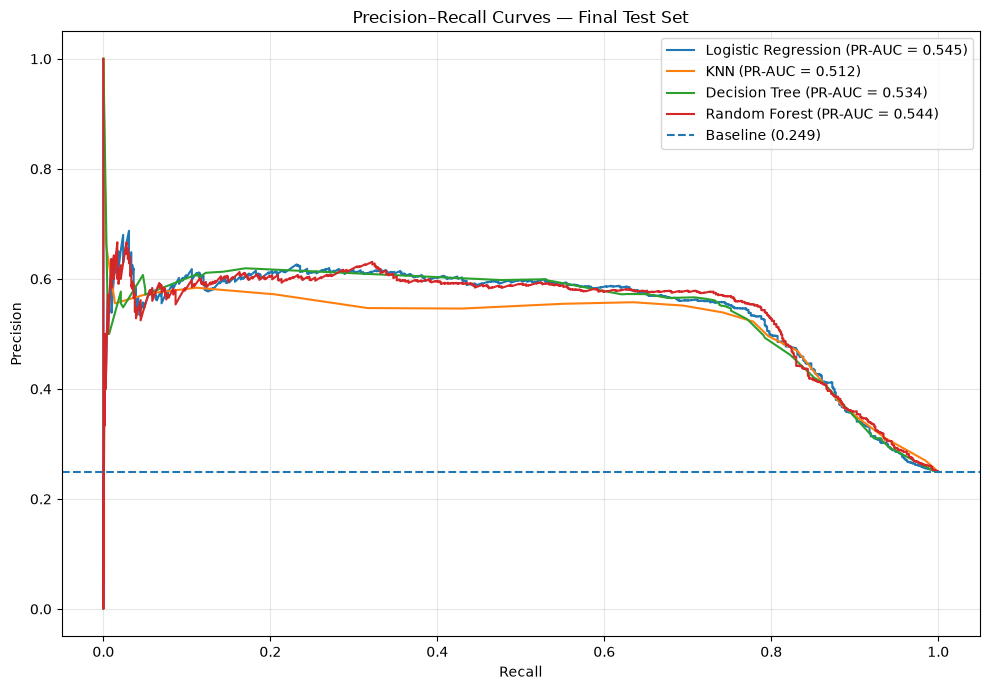

In [85]:
plt.figure(figsize=(10, 7))
positive_rate = y_test.mean()

for name, data in pr_curve_data.items():
    pr_auc = average_precision_score(y_test,test_probabilities[name])
    plt.plot(
        data["recall"],
        data["precision"],
        label=f"{name} (PR-AUC = {pr_auc:.3f})"
    )

plt.axhline(positive_rate,linestyle="--",label=f"Baseline ({positive_rate:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves — Final Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    plots_dir / "precision_recall_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [66]:
calibration_data = {}

for name, probabilities in test_probabilities.items():
    fraction_of_positives, mean_predicted_value = calibration_curve(
        y_test,
        probabilities,
        n_bins=10,
        strategy="uniform"
    )

    calibration_data[name] = {
        "fraction_of_positives": fraction_of_positives,
        "mean_predicted_value": mean_predicted_value
    }

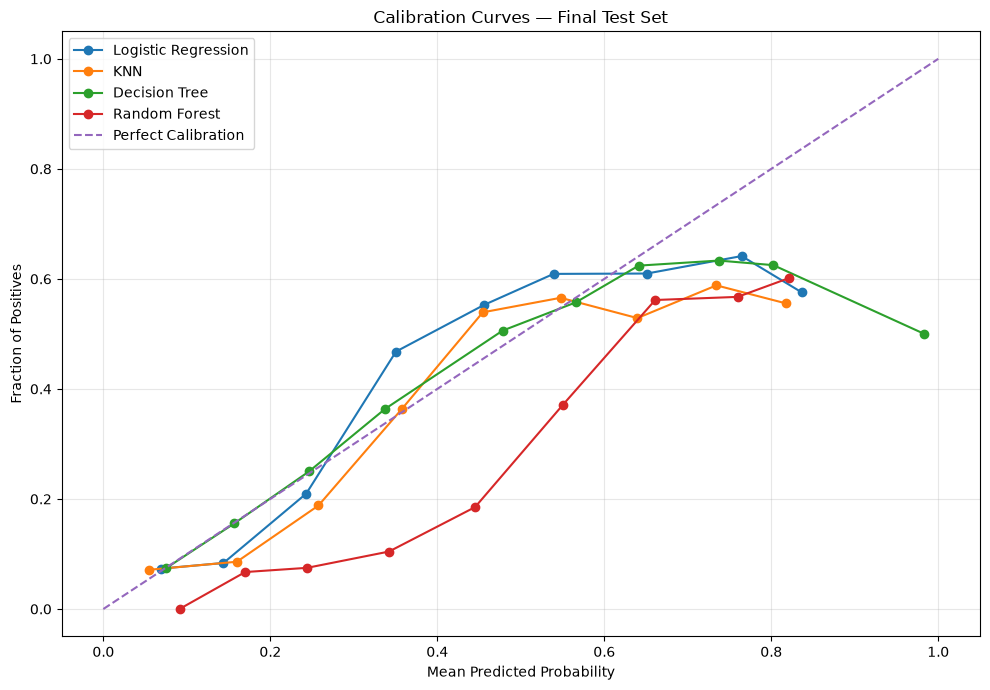

In [86]:
plt.figure(figsize=(10, 7))

for name, data in calibration_data.items():
    plt.plot(
        data["mean_predicted_value"],
        data["fraction_of_positives"],
        marker="o",
        label=name
    )

plt.plot([0, 1],[0, 1],linestyle="--",label="Perfect Calibration")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Curves — Final Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    plots_dir / "calibration_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [68]:
comparison_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Balanced Accuracy",
    "ROC-AUC",
    "PR-AUC"
]

metric_comparison_df = final_test_df[["Model"] + comparison_metrics].copy()
metric_comparison_df

,Model,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC,PR-AUC
0,Logistic Regression,0.788796,0.557895,0.739191,0.635873,0.772238,0.806008,0.545018
1,Random Forest,0.795407,0.568690,0.744770,0.644928,0.778505,0.809383,0.544331
2,Decision Tree,0.786708,0.554507,0.737796,0.633154,0.770382,0.803015,0.534296
3,KNN,0.777314,0.539007,0.741980,0.624413,0.765520,0.798552,0.511702


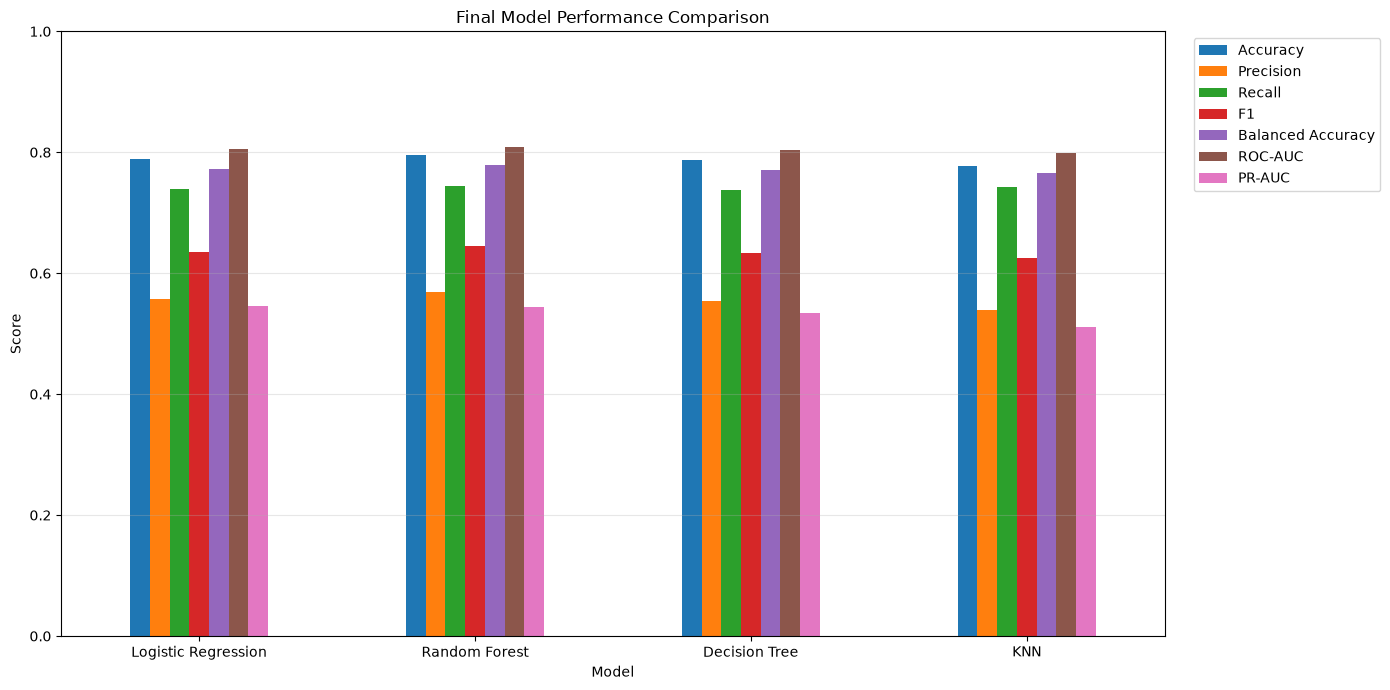

In [87]:
plot_df = metric_comparison_df.set_index("Model")
ax = plot_df.plot(kind="bar",figsize=(14, 7))

ax.set_title("Final Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1),loc="upper left")
plt.grid(axis="y",alpha=0.3)
plt.tight_layout()

plt.savefig(
    plots_dir / "model_metric_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [70]:
baseline_pr_auc = {
    row["Model"]: row["PR-AUC"]
    for _, row in baseline_cv_df.iterrows()
}

tuned_pr_auc = {
    row["Model"]: row["Best PR-AUC"]
    for _, row in tuning_summary_df.iterrows()
}

tuning_comparison_df = pd.DataFrame({
    "Model": list(baseline_pr_auc.keys()),
    "Baseline PR-AUC": [
        baseline_pr_auc[name]
        for name in baseline_pr_auc.keys()
    ],
    "Tuned PR-AUC": [
        tuned_pr_auc[name]
        for name in baseline_pr_auc.keys()
    ]
})

tuning_comparison_df

,Model,Baseline PR-AUC,Tuned PR-AUC
0,Logistic Regression,0.539324,0.542403
1,Random Forest,0.528629,0.553074
2,KNN,0.459024,0.524014
3,Decision Tree,0.341050,0.524982


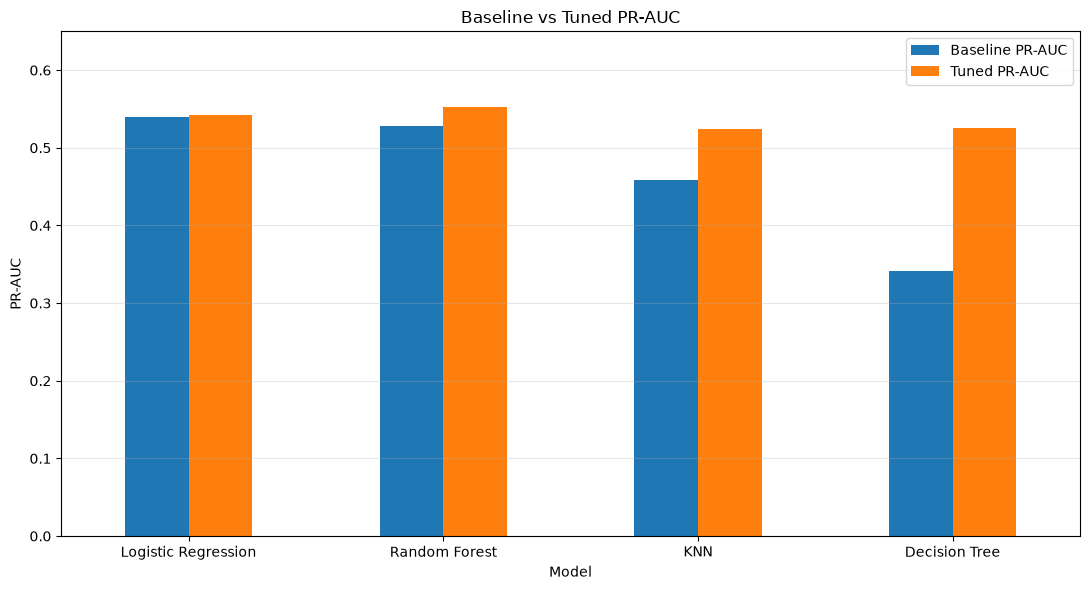

In [71]:
tuning_plot_df = tuning_comparison_df.set_index("Model")
ax = tuning_plot_df.plot(kind="bar",figsize=(11, 6))
ax.set_title("Baseline vs Tuned PR-AUC")
ax.set_ylabel("PR-AUC")
ax.set_xlabel("Model")
ax.set_ylim(0, 0.65)

plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y",alpha=0.3)
plt.tight_layout()
plt.show()

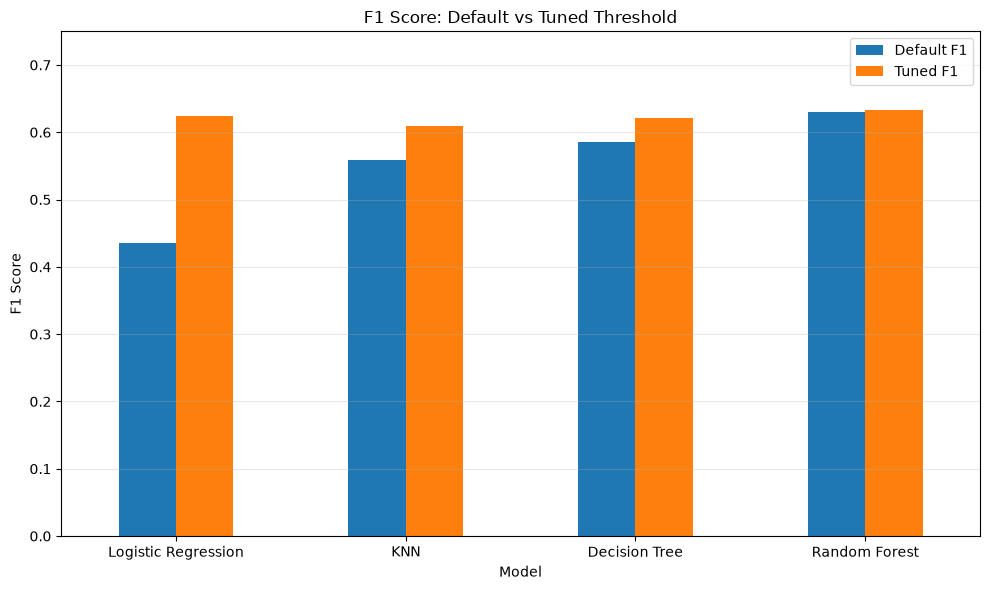

In [72]:
threshold_plot_df = threshold_comparison_df[["Model","Default F1","Tuned F1"]].set_index("Model")

ax = threshold_plot_df.plot(kind="bar",figsize=(10, 6))
ax.set_title("F1 Score: Default vs Tuned Threshold")
ax.set_ylabel("F1 Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 0.75)

plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y",alpha=0.3)
plt.tight_layout()
plt.show()

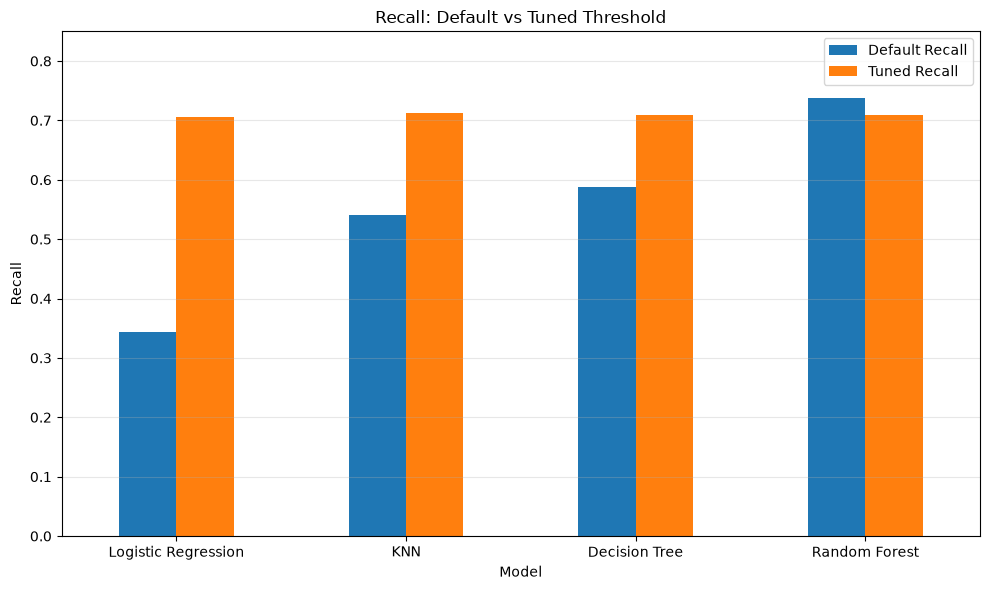

In [73]:
recall_plot_df = threshold_comparison_df[["Model","Default Recall","Tuned Recall"]].set_index("Model")
ax = recall_plot_df.plot(kind="bar",figsize=(10, 6))
ax.set_title("Recall: Default vs Tuned Threshold")
ax.set_ylabel("Recall")
ax.set_xlabel("Model")
ax.set_ylim(0, 0.85)

plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y",alpha=0.3)
plt.tight_layout()
plt.show()

In [74]:
from sklearn.inspection import permutation_importance

In [75]:
best_model_name = "Random Forest"
best_model = final_models[best_model_name]

print(f"Calculating permutation importance for {best_model_name}...")
rf_permutation = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
print("Permutation importance completed.")

Calculating permutation importance for Random Forest...
Permutation importance completed.


In [76]:
rf_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": rf_permutation.importances_mean,
    "Importance Std": rf_permutation.importances_std
})

rf_importance_df = rf_importance_df.sort_values("Importance Mean", ascending=False).reset_index(drop=True)
rf_importance_df

,Feature,Importance Mean,Importance Std
0,city_development_index,0.059409,0.010426
1,company_size,0.031782,0.005911
2,city,0.031734,0.007380
3,company_type,0.007967,0.007889
4,education_level,0.007838,0.003470
5,relevent_experience,0.004729,0.003364
6,last_new_job_numeric,0.002819,0.003956
7,major_discipline,0.002668,0.002102
8,training_hours,0.001891,0.003720
9,experience_missing,0.000072,0.000105


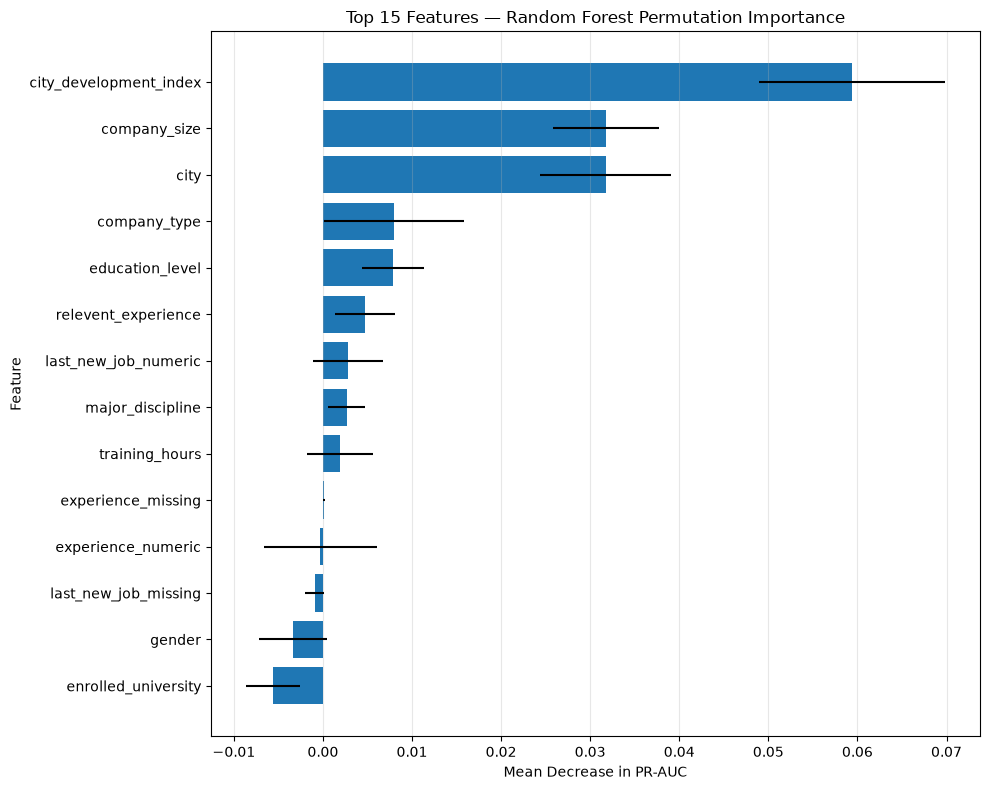

In [88]:
top_n = 15
top_features = rf_importance_df.head(top_n).sort_values("Importance Mean")

plt.figure(figsize=(10, 8))
plt.barh(top_features["Feature"],top_features["Importance Mean"],xerr=top_features["Importance Std"])
plt.xlabel("Mean Decrease in PR-AUC")
plt.ylabel("Feature")
plt.title("Top 15 Features — Random Forest Permutation Importance")
plt.grid(axis="x",alpha=0.3)
plt.tight_layout()

plt.savefig(
    plots_dir / "random_forest_permutation_importance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## Saving models and metrices

In [89]:
from pathlib import Path
import pickle
import json

artifacts_dir = Path("../artifacts")

models_dir = artifacts_dir / "models"
metrics_dir = artifacts_dir / "metrics"
tuning_dir = artifacts_dir / "tuning"
metadata_dir = artifacts_dir / "metadata"

In [90]:
model_file_names = {
    "Logistic Regression": "logistic_regression.pkl",
    "KNN": "knn.pkl",
    "Decision Tree": "decision_tree.pkl",
    "Random Forest": "random_forest.pkl"
}

for name, model in final_models.items():
    file_path = models_dir / model_file_names[name]
    with open(file_path, "wb") as file:
        pickle.dump(model, file)
    print(f"Saved: {file_path}")

Saved: ..\artifacts\models\logistic_regression.pkl
Saved: ..\artifacts\models\knn.pkl
Saved: ..\artifacts\models\decision_tree.pkl
Saved: ..\artifacts\models\random_forest.pkl


In [91]:
for name, file_name in model_file_names.items():
    file_path = models_dir / file_name
    print(
        f"{name}: "
        f"{file_path.exists()} | "
        f"{file_path.stat().st_size / (1024 * 1024):.2f} MB"
    )

Logistic Regression: True | 0.01 MB
KNN: True | 2.80 MB
Decision Tree: True | 0.02 MB
Random Forest: True | 14.88 MB


In [92]:
final_test_df.to_csv(metrics_dir / "final_test_metrics.csv",index=False)
print("Saved final_test_metrics.csv")

Saved final_test_metrics.csv


In [93]:
baseline_cv_df.to_csv(metrics_dir / "baseline_cv_metrics.csv",index=False)
print("Saved baseline_cv_metrics.csv")

Saved baseline_cv_metrics.csv


In [94]:
tuning_summary_df.to_csv(metrics_dir / "tuning_summary.csv",index=False)
print("Saved tuning_summary.csv")

Saved tuning_summary.csv


In [95]:
threshold_comparison_df.to_csv(metrics_dir / "threshold_comparison.csv",index=False)
best_threshold_df.to_csv(metrics_dir / "best_thresholds.csv",index=False)
print("Saved threshold result files.")

Saved threshold result files.


In [96]:
cv_vs_test_df.to_csv(metrics_dir / "cv_vs_test.csv",index=False)
print("Saved cv_vs_test.csv")

Saved cv_vs_test.csv


In [97]:
best_parameters = {}

for name, search in tuned_models.items():
    best_parameters[name] = {
        parameter: str(value)
        for parameter, value in search.best_params_.items()
    }

with open(tuning_dir / "best_parameters.json","w",encoding="utf-8") as file:
    json.dump(
        best_parameters,
        file,
        indent=4
    )

print("Saved best_parameters.json")

Saved best_parameters.json


In [98]:
with open(metadata_dir / "selected_thresholds.json","w",encoding="utf-8") as file:
    json.dump(
        selected_thresholds,
        file,
        indent=4
    )

print("Saved selected_thresholds.json")

Saved selected_thresholds.json


In [99]:
feature_metadata = {
    "id_column": ID_COLUMN,
    "target_column": TARGET_COLUMN,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "all_model_features": list(X_train.columns),
    "number_of_model_features": len(X_train.columns),
    "processed_feature_count": 145
}

with open(metadata_dir / "feature_metadata.json","w",encoding="utf-8") as file:
    json.dump(
        feature_metadata,
        file,
        indent=4
    )

print("Saved feature_metadata.json")

Saved feature_metadata.json


In [100]:
rf_importance_df.to_csv(metrics_dir / "random_forest_permutation_importance.csv",index=False)
print("Saved random_forest_permutation_importance.csv")

Saved random_forest_permutation_importance.csv


In [101]:
print("ARTIFACT STRUCTURE")
print("=" * 70)

for path in sorted(artifacts_dir.rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(artifacts_dir)}")

ARTIFACT STRUCTURE
metadata\feature_metadata.json
metadata\selected_thresholds.json
metrics\baseline_cv_metrics.csv
metrics\best_thresholds.csv
metrics\cv_vs_test.csv
metrics\final_test_metrics.csv
metrics\random_forest_permutation_importance.csv
metrics\threshold_comparison.csv
metrics\tuning_summary.csv
models\decision_tree.pkl
models\knn.pkl
models\logistic_regression.pkl
models\random_forest.pkl
plots\calibration_curves.png
plots\confusion_matrices.png
plots\model_metric_comparison.png
plots\precision_recall_curves.png
plots\random_forest_permutation_importance.png
plots\roc_curves.png
tuning\best_parameters.json


In [102]:
loaded_models = {}

for name, file_name in model_file_names.items():
    file_path = models_dir / file_name
    with open(file_path, "rb") as file:
        loaded_models[name] = pickle.load(file)

    print(f"{name}: loaded successfully")

Logistic Regression: loaded successfully
KNN: loaded successfully
Decision Tree: loaded successfully
Random Forest: loaded successfully


In [103]:
sample_input = X_test.iloc[[0]]

print("Testing loaded models on one test sample:")
print("=" * 60)

for name, model in loaded_models.items():
    probability = model.predict_proba(sample_input)[0, 1]
    threshold = selected_thresholds[name]
    prediction = int(probability >= threshold)

    print(
        f"{name}: "
        f"Prediction={prediction}, "
        f"Probability={probability:.4f}, "
        f"Threshold={threshold:.2f}"
    )

Testing loaded models on one test sample:
Logistic Regression: Prediction=0, Probability=0.0759, Threshold=0.30
KNN: Prediction=0, Probability=0.1905, Threshold=0.34
Decision Tree: Prediction=0, Probability=0.0896, Threshold=0.31
Random Forest: Prediction=0, Probability=0.3027, Threshold=0.56
